In [ ]:
#import random
import torch as tc
import numpy as np
import qutip as qt
#import sys
#sys.path.insert(0, '../../PopsCtrl/')
#import function as my
import matplotlib.pyplot as plt
import random
from tqdm import tqdm
import torch.nn as nn


device = tc.device('cuda' if tc.cuda.is_available() else 'cpu')
print(f"Executing in device: {device}")

if device.type == 'cpu':
  num_threads = 10
  tc.set_num_threads(num_threads)
  tc.set_num_interop_threads(num_threads)
  print(f"Threads set to: {tc.get_num_threads()}")


Executando no dispositivo: cpu
Threads set to: 10


In [15]:

def generate_random_fields(num_qubits=2, num_terms=3, seed=None):
    """
    Gera funções de campo para múltiplos qubits com amplitudes, frequências
    e fases sorteadas aleatoriamente.
    """
    if seed is not None:
        np.random.seed(seed)
        
    num_fields = num_qubits * 3
    
    # Sorteio aleatório dos parâmetros para os num_fields campos
    amplitudes = np.random.uniform(-2.0*np.pi, 2.0*np.pi, size=(num_fields, num_terms))
    frequencies = np.random.uniform(0.5, 6.0, size=(num_fields, num_terms))
    phases = np.random.uniform(0.0, 2 * np.pi, size=(num_fields, num_terms))
    funcs = [np.sin, np.cos]  # Alternância de funções trigonométricas

    def fields(t):
        t_arr = np.atleast_1d(t)
        field_values = np.zeros((num_fields, len(t_arr)))
        
        for idx in range(num_fields):
            field_sum = np.zeros(len(t_arr))
            for term in range(num_terms):
                # Seleciona sin ou cos de forma cíclica
                func = funcs[term % len(funcs)]
                amp = amplitudes[idx, term]
                freq = frequencies[idx, term]
                phase = phases[idx, term]
                
                field_sum += amp * func(freq * t_arr + phase)
            
            field_values[idx, :] = field_sum #*np.sin(2*np.pi*t)
            
        # Se a entrada foi um escalar, retorna array (6,) em vez de (6, 1)
        return field_values.squeeze()

    return fields

# Exemplo de uso:
fields_2qubits = generate_random_fields(num_qubits=2, num_terms=3, seed=22)

# Exemplo avaliando no tempo t = 0 ou em um array de tempos:
tlist = np.linspace(0.0, 1.0, 800)
fields_array = fields_2qubits(tlist)  # Formato da saída: (6, 400)

In [16]:
def data_qubit(Js,dissipation,tlist,O_op,H_op,fields_array,psi0,device):
    H = []
    for i in range(len(H_op)):
        H.append([0.5 * H_op[i], fields_array[i, :]])
    # for i in range(len(fields_array),len(O_op)):
    #     H.append(0.5 *Js[i-len(fields_array)]*O_op[i])        

    # Hamiltonian Lindbladian
    c_ops = [np.sqrt(dissipation[0])*qt.tensor(qt.sigmam(), qt.qeye(2)),
             np.sqrt(dissipation[1])*qt.tensor(qt.sigmaz(), qt.qeye(2)),
             np.sqrt(dissipation[2])*qt.tensor(qt.qeye(2) , qt.sigmam()),
             np.sqrt(dissipation[3])*qt.tensor(qt.qeye(2) , qt.sigmaz())]
    # Solução da equação de Schrödinger
    options = {"nsteps": 100000, "atol": 1e-14, "rtol": 1e-14}
    result  = qt.mesolve(H, psi0, tlist, c_ops=c_ops, e_ops=O_op,options=options)

    expect  = tc.tensor( np.array(result.expect),device = device).transpose(0, 1)
    return expect


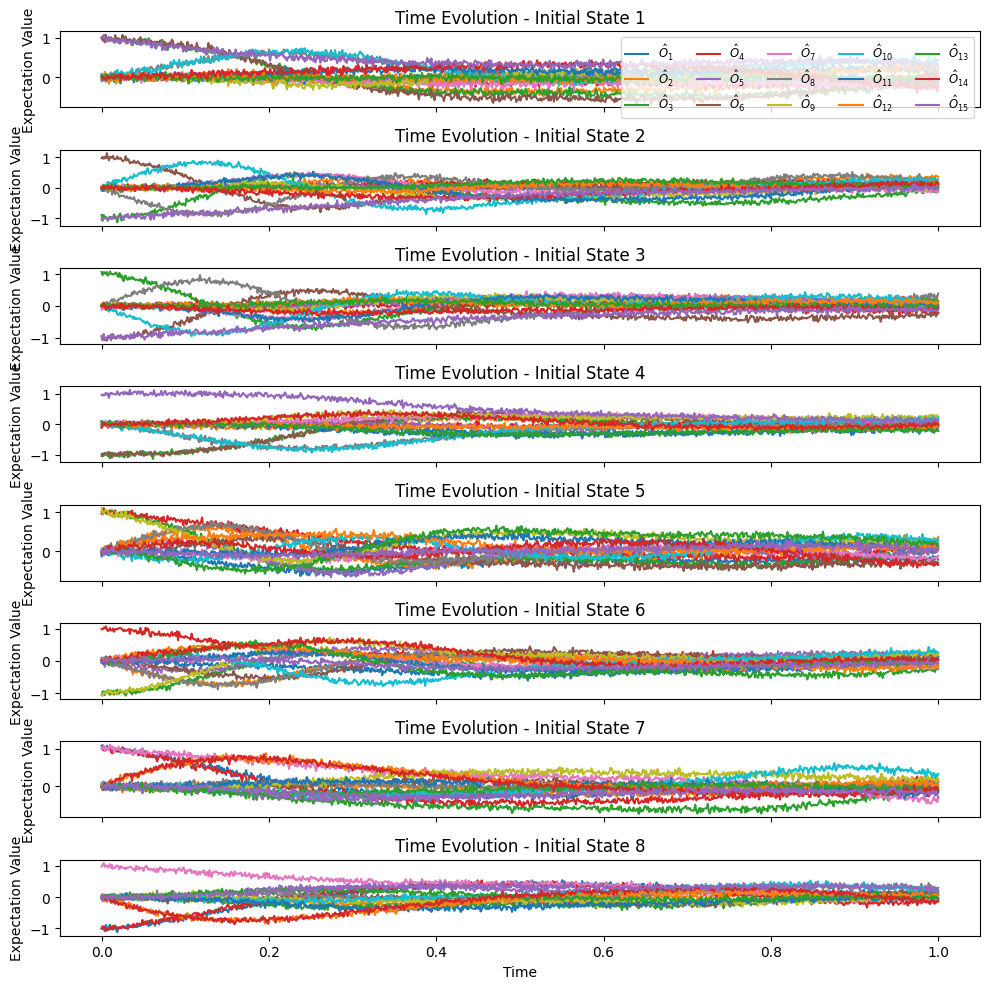

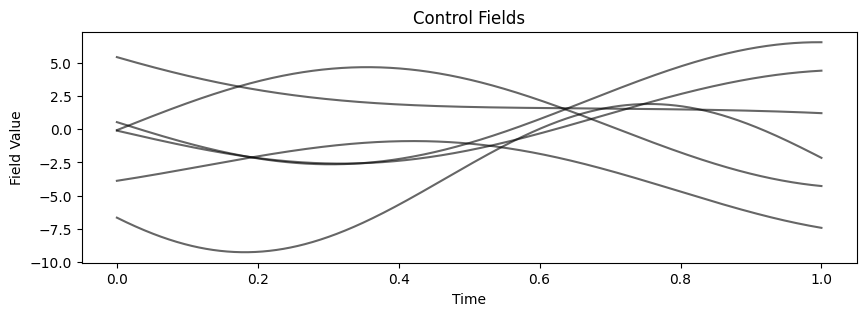

In [17]:
SEED = 14
np.random.seed(SEED)
tc.manual_seed(SEED) 
random.seed(SEED)

# Device configuration
device = tc.device("cuda" if tc.cuda.is_available() else "cpu")

# Operadores de Pauli para cada qubit (15 Observáveis)
IX, IY, IZ = qt.tensor(qt.qeye(2), qt.sigmax()), qt.tensor(qt.qeye(2), qt.sigmay()), qt.tensor(qt.qeye(2), qt.sigmaz())
XI, YI, ZI = qt.tensor(qt.sigmax(), qt.qeye(2)), qt.tensor(qt.sigmay(), qt.qeye(2)), qt.tensor(qt.sigmaz(), qt.qeye(2))
XX, XY, XZ = qt.tensor(qt.sigmax(), qt.sigmax()), qt.tensor(qt.sigmax(), qt.sigmay()), qt.tensor(qt.sigmax(), qt.sigmaz())
YX, YY, YZ = qt.tensor(qt.sigmay(), qt.sigmax()), qt.tensor(qt.sigmay(), qt.sigmay()), qt.tensor(qt.sigmay(), qt.sigmaz())
ZX, ZY, ZZ = qt.tensor(qt.sigmaz(), qt.sigmax()), qt.tensor(qt.sigmaz(), qt.sigmay()), qt.tensor(qt.sigmaz(), qt.sigmaz())

O_op = [IX, IY, IZ, 
        XI, YI, ZI, 
        XX, XY, XZ, 
        YX, YY, YZ, 
        ZX, ZY, ZZ ]


H_op = [IZ, ZI, IX, XX, YY, ZZ]

tfinal = 1.0
N = 800
sig = 0.05# Standard deviation for Gaussian noise
tlist = np.linspace(0.0, tfinal, N)


Js = [2*np.pi*random.uniform(-1, 1) for _ in range(9)]
dissipation = [random.uniform(0, 1) for _ in range(4)]

# Base dos estados de 1 qubit: |0>, |1>, |+>, |->, |+i>, |-i>
q0 = qt.basis(2, 0)
q1 = qt.basis(2, 1)
qx_plus = (q0 + q1).unit()
qx_minus = (q0 - q1).unit()
qy_plus = (q0 + 1j * q1).unit()
qy_minus = (q0 - 1j * q1).unit()

# Conjunto de 16 Estados Iniciais (Produtos de Pauli + Estados Emaranhados de Bell)
psi_iniciais = [
    # Produtos da base computacional / superposições
    qt.tensor(q0, q0),            # |00>
    qt.tensor(q0, q1),            # |01>
    qt.tensor(q1, q0),            # |10>
    qt.tensor(q1, q1),            # |11>
    qt.tensor(qx_plus, q0),       # |+0>
    qt.tensor(qx_plus, q1),       # |+1>
    qt.tensor(qx_plus, qx_plus),  # |++>
    qt.tensor(qx_minus, qx_minus), #,# |-- >
    qt.tensor(qy_plus, q0),       # |+i, 0>
    qt.tensor(qy_plus, qy_plus),  # |+i, +i>
    qt.tensor(qy_minus, qy_minus),# |-i, -i>
    qt.tensor(qx_plus, qy_plus)  # |+, +i>
    
    # # Estados de Bell Emaranhados (Essenciais para termos de acoplamento J_ij)
    # (qt.tensor(q0, q0) + qt.tensor(q1, q1)).unit(), # |Phi+>
    # (qt.tensor(q0, q0) - qt.tensor(q1, q1)).unit(), # |Phi->
    # (qt.tensor(q0, q1) + qt.tensor(q1, q0)).unit(), # |Psi+>
    # (qt.tensor(q0, q1) - qt.tensor(q1, q0)).unit()  # |Psi->
]

# Simulação e Armazenamento dos Resultados
lista_valor_esperado_data = []

for idx,psi0 in enumerate(psi_iniciais):
    val_data = data_qubit(Js, dissipation, tlist, O_op, H_op, fields_array, psi0, device)
    val_data += tc.tensor(np.random.normal(0, sig, val_data.shape), device=device)  # Adiciona ruído gaussiano
    lista_valor_esperado_data.append(val_data)

# Visualização dos Primeiros 3 Estados Gerados
fig, axes = plt.subplots(8, 1, figsize=(10, 10), sharex=True)

for estado_idx in range(8):
    data_estado = lista_valor_esperado_data[estado_idx].cpu().numpy()
    for i in range(len(O_op)):
        axes[estado_idx].plot(tlist, data_estado[:, i], label=fr"$\hat{{O}}_{{{i+1}}}$" if estado_idx == 0 else "")
    
    axes[estado_idx].set_ylabel('Expectation Value')
    axes[estado_idx].set_title(f'Time Evolution - Initial State {estado_idx + 1}')

axes[0].legend(ncols=5, loc='upper right', fontsize='small')
axes[-1].set_xlabel('Time')
plt.tight_layout()
plt.show()

# Gráfico dos Campos de Controle
plt.figure(figsize=(10, 3))
plt.plot(tlist, fields_array[0:6,:].T, 'k-', alpha=0.6)
plt.xlabel('Time')
plt.ylabel('Field Value')
plt.title('Control Fields')
plt.show()

In [18]:

class FourierFeatures(nn.Module):
    def __init__(self, n_freq=16, f_max=3.0, trainable=False):
        super().__init__()
        # Frequências baixas e igualmente espaçadas (de 0.1*f_max até f_max)
        freqs = tc.linspace(0.1 * f_max, f_max, n_freq).unsqueeze(1) # Shape: (n_freq, 1)
        # Fixar trainable=False para impedir que o otimizador crie frequências espúrias
        self.B = nn.Parameter(freqs, requires_grad=trainable)

    def forward(self, t):
        if t.dim() == 1:
            t = t[:, None]
        # t: (N, 1), B: (n_freq, 1) -> x: (N, n_freq)
        x = t @ self.B.T
        return tc.cat([tc.sin(x), tc.cos(x)], dim=-1)
class Rede(nn.Module):
    def __init__(self, neuronio, activation, input_=1, output_=1,
                 creat_p=False, N_of_paramater=1, dropout_prob=0.0,
                 use_fourier=False, n_freq=32, f_max=10.0):
        super().__init__()

        self.neuronio = neuronio
        self.output = output_
        self.creat_p = creat_p
        self.N_of_paramater = N_of_paramater
        self.dropout_prob = dropout_prob
        self.use_fourier = use_fourier

        if use_fourier:
            # CHAMADA CORRIGIDA AQUI:
            self.ff = FourierFeatures(n_freq=n_freq, f_max=f_max, trainable=False)
            first_in = 2 * n_freq
        else:
            self.ff = None
            first_in = input_

        self.hidden_layers = nn.ModuleList([nn.Linear(first_in, neuronio[0])])
        self.hidden_layers.extend(
            [nn.Linear(neuronio[_], neuronio[_+1]) for _ in range(len(neuronio)-1)]
        )
        self.output_layer = nn.Linear(neuronio[-1], output_)

        self.activation_ = activation
        self.dropouts = nn.ModuleList([nn.Dropout(dropout_prob) for _ in range(len(neuronio))])

        if creat_p:
            self.parametro = nn.Parameter(tc.rand(N_of_paramater))

    def forward(self, x):
        if self.ff is not None:
            x = self.ff(x)

        for layer, activation, dropout in zip(self.hidden_layers, self.activation_, self.dropouts):
            x = activation(layer(x))
            x = dropout(x)

        x = self.output_layer(x)
        return x        
    
class SIN(tc.nn.Module):
    def __init__(self):
        super(SIN, self).__init__()
    def forward(self, x):
        return tc.sin(x)

In [ ]:
N4=800
NUM_OBSERVAVEIS = 15  
NUM_CAMPOS = 6       
dados_esperados = [d.to(device) for d in lista_valor_esperado_data] 
NUM_ESTADOS = len(dados_esperados)             # 4 estados
IDX_DIVISAO_CAMPOS = NUM_ESTADOS * NUM_OBSERVAVEIS  # Índice 16 (0 a 15 são observáveis)

# Rede 1: Aprende as trajetórias dos observáveis
Rede_Estados = Rede(
    neuronio=[128, 128, 128],
    input_=1,
    output_=NUM_ESTADOS * NUM_OBSERVAVEIS,
    activation=[SIN()]*3,
    creat_p=True,
    N_of_paramater=0,
    use_fourier=True,
    n_freq=16,
    f_max=6.0
).to(device)

# Rede 2: Aprende apenas os campos de controle
Rede_Campos = Rede(
    neuronio=[128, 128, 128],
    input_=1,
    output_=NUM_CAMPOS,
    activation=[SIN()]*3,
    creat_p=False,    
    use_fourier=True,
    n_freq=32,
    f_max=6.0
).to(device)

time =  tc.linspace(
        0,
        tfinal,
        N4,
        dtype   = tc.float32,
        requires_grad = True).reshape((-1, 1))
time = time.to(device)




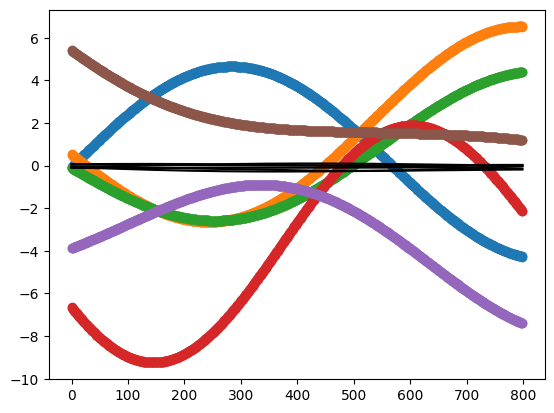

In [20]:
X_=Rede_Campos(time).cpu().detach().numpy()
plt.plot(np.transpose(fields_array[0:6,:]),'o')
for i in range(0,6):
    plt.plot(X_[:,i],"k")



plt.show()


In [21]:
def calcular_residuos_edo_15obs_full_time_dep(y_slice, dX_dt_slice, parametro, j_fields):
    IX, IY, IZ, XI, YI, ZI, XX, XY, XZ, YX, YY, YZ, ZX, ZY, ZZ = [y_slice[:, i:i+1] for i in range(15)]
    dIX, dIY, dIZ, dXI, dYI, dZI, dXX, dXY, dXZ, dYX, dYY, dYZ, dZX, dZY, dZZ = [dX_dt_slice[:, i:i+1] for i in range(15)]
    

    gamma1, gamma2, gamma3, gamma4 = parametro
    J_IZ, J_ZI, J_IX, J_XX, J_YY, J_ZZ = j_fields

    loss_block = 0.0

    # Qubit 2
    loss_block += (dIX - (-1.0*J_IZ*IY + 1.0*J_YY*YZ - 1.0*J_ZZ*ZY + IX*(-0.5*gamma3 - 2.0*gamma4)))**2
    loss_block += (dIY - (+1.0*J_IZ*IX - 1.0*J_IX*IZ - 1.0*J_XX*XZ + 1.0*J_ZZ*ZX + IY*(-0.5*gamma3 - 2.0*gamma4)))**2
    loss_block += (dIZ - (+1.0*J_IX*IY + 1.0*J_XX*XY - 1.0*J_YY*YX + (IZ + 1.0)*(-1.0*gamma3)))**2

    # Qubit 1
    loss_block += (dXI - (-1.0*J_ZI*YI + 1.0*J_YY*ZY - 1.0*J_ZZ*YZ + XI*(-0.5*gamma1 - 2.0*gamma2)))**2
    loss_block += (dYI - (+1.0*J_ZI*XI - 1.0*J_XX*ZX + 1.0*J_ZZ*XZ + YI*(-0.5*gamma1 - 2.0*gamma2)))**2
    loss_block += (dZI - (+1.0*J_XX*YX - 1.0*J_YY*XY + (ZI + 1.0)*(-1.0*gamma1)))**2

    # Correlações
    loss_block += (dXX - (-1.0*J_IZ*XY - 1.0*J_ZI*YX + XX*(-0.5*gamma1 - 2.0*gamma2 - 0.5*gamma3 - 2.0*gamma4)))**2
    loss_block += (dXY - (+1.0*J_IZ*XX - 1.0*J_ZI*YY - 1.0*J_IX*XZ - 1.0*J_XX*IZ + 1.0*J_YY*ZI + XY*(-0.5*gamma1 - 2.0*gamma2 - 0.5*gamma3 - 2.0*gamma4)))**2
    loss_block += (dXZ - (-1.0*J_ZI*YZ + 1.0*J_IX*XY + 1.0*J_XX*IY - 1.0*J_ZZ*YI + XZ*(-0.5*gamma1 - 2.0*gamma2 - 1.0*gamma3) + XI*(-1.0*gamma3)))**2

    loss_block += (dYX - (-1.0*J_IZ*YY + 1.0*J_ZI*XX - 1.0*J_XX*ZI + 1.0*J_YY*IZ + YX*(-0.5*gamma1 - 2.0*gamma2 - 0.5*gamma3 - 2.0*gamma4)))**2
    loss_block += (dYY - (+1.0*J_IZ*YX + 1.0*J_ZI*XY - 1.0*J_IX*YZ + YY*(-0.5*gamma1 - 2.0*gamma2 - 0.5*gamma3 - 2.0*gamma4)))**2
    loss_block += (dYZ - (+1.0*J_ZI*XZ + 1.0*J_IX*YY - 1.0*J_YY*IX + 1.0*J_ZZ*XI + YZ*(-0.5*gamma1 - 2.0*gamma2 - 1.0*gamma3) + YI*(-1.0*gamma3)))**2

    loss_block += (dZX - (-1.0*J_IZ*ZY + 1.0*J_XX*YI - 1.0*J_ZZ*IY + ZX*(-1.0*gamma1 - 0.5*gamma3 - 2.0*gamma4) + IX*(-1.0*gamma1)))**2
    loss_block += (dZY - (+1.0*J_IZ*ZX - 1.0*J_IX*ZZ - 1.0*J_YY*XI + 1.0*J_ZZ*IX + ZY*(-1.0*gamma1 - 0.5*gamma3 - 2.0*gamma4) + IY*(-1.0*gamma1)))**2
    loss_block += (dZZ - (+1.0*J_IX*ZY + ZZ*(-1.0*gamma1 - 1.0*gamma3) + IZ*(-1.0*gamma1) + ZI*(-1.0*gamma3)))**2

    return loss_block


In [22]:
import torch as tc
import numpy as np
from scipy.interpolate import CubicSpline


# ==============================================================================
# ESTÁGIO 1 & 2: Derivadas Analíticas Ultra-Suaves via Splines Cúbicas
# ==============================================================================
print("Calculando derivadas analíticas ultra-suaves via Spline Cúbica...")

t_np = time.squeeze().detach().cpu().numpy()
y_spline_list = []
dY_dt_spline_list = []

for s in range(NUM_ESTADOS):
    # Dados do QuTiP para o estado s
    y_real_np = dados_esperados[s].cpu().numpy() # Shape: (N, 15)
    
    # Ajusta Spline Cúbica ponto a ponto
    cs = CubicSpline(t_np, y_real_np, axis=0)
    
    # Avalia a spline e sua derivada analítica exata (nu=1)
    y_smooth = cs(t_np)
    dy_dt_smooth = cs(t_np, nu=1)
    
    y_spline_list.append(tc.tensor(y_smooth, dtype=tc.float32, device=device))
    dY_dt_spline_list.append(tc.tensor(dy_dt_smooth, dtype=tc.float32, device=device))

y_fixo_spline = tc.cat(y_spline_list, dim=1)        # Shape: (N, 240)
dX_dt_fixo_spline = tc.cat(dY_dt_spline_list, dim=1) # Shape: (N, 240)

print("Derivadas calculadas! Iniciando otimização da Rede_Campos...")

# ==============================================================================
# ESTÁGIO 3: Otimizar APENAS a Rede_Campos com Derivadas da Spline
# ==============================================================================
opt_campos = tc.optim.Adam(Rede_Campos.parameters(), lr=1e-3)
scheduler_cam = tc.optim.lr_scheduler.ReduceLROnPlateau(opt_campos, mode='min', factor=0.5, patience=200)

param_qutip = tc.tensor([0.0, 0.0, 0.0, 0.0], device=device) # Gammas fixos em 0

for epoca in range(1500):
    opt_campos.zero_grad()
    
    # Rede de campos prevê J(t)
    z = Rede_Campos(time)
    j_fields = [z[:, i:i+1] for i in range(6)]

    loss_edo = 0.0
    for estado_idx in range(NUM_ESTADOS):
        idx_start = estado_idx * NUM_OBSERVAVEIS
        idx_end = idx_start + NUM_OBSERVAVEIS

        # Usa os estados e derivadas SUAVES da Spline
        y_cond = y_fixo_spline[:, idx_start:idx_end]
        dX_dt_cond = dX_dt_fixo_spline[:, idx_start:idx_end]

        residuos = calcular_residuos_edo_15obs_full_time_dep(y_cond, dX_dt_cond, param_qutip, j_fields)
        loss_edo += residuos.mean()

    loss_edo /= NUM_ESTADOS

    loss_edo.backward()
    opt_campos.step()
    scheduler_cam.step(loss_edo)

    if (epoca + 1) % 500 == 0:
        print(f"Época {epoca+1} | Loss EDO: {loss_edo.item():.2e}")


Calculando derivadas analíticas ultra-suaves via Spline Cúbica...
Derivadas calculadas! Iniciando otimização da Rede_Campos...
Época 500 | Loss EDO: 3.45e+04
Época 1000 | Loss EDO: 3.45e+04
Época 1500 | Loss EDO: 3.44e+04


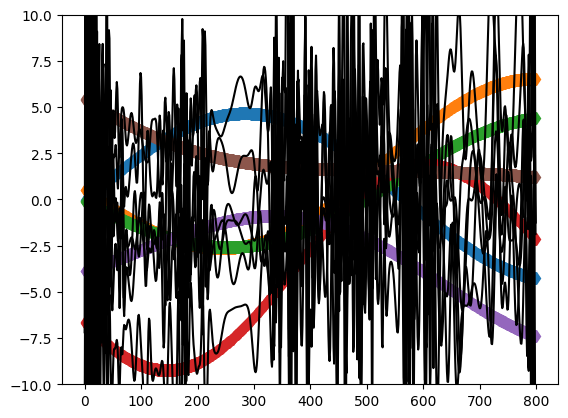

tensor([0., 0., 0., 0.])


In [23]:
X_=Rede_Campos(time).cpu().detach().numpy()
plt.plot(np.transpose(fields_array[0:6,:]),'d')
for i in range(6):
    plt.plot(X_[:,i],"k")
plt.ylim(-10,10)


plt.show()
print(param_qutip)


In [13]:
import torch as tc
import numpy as np

# ==============================================================================
# FASE 3A: Otimizar APENAS os Gammas (Rede_Campos CONGELADA)
# ==============================================================================
# param_gamma = -5.0 resulta em softplus(-5.0) ~ 0.0067 (próximo de zero)
param_gamma = tc.nn.Parameter(tc.tensor([-5.0, -5.0, -5.0, -5.0], device=device))

opt_gamma = tc.optim.Adam([param_gamma], lr=1e-2)

# Hiperparâmetro L1: empurrar os gammas para zero quando desnecessários
lambda_l1 = 0e-3 

print("Fase 3A: Ajustando APENAS os Gammas (Rede_Campos congelada)...")
for epoca in range(1000):
    opt_gamma.zero_grad()
    
    gammas_positivos = tc.nn.functional.softplus(param_gamma)
    
    # Avalia a Rede_Campos sem calcular gradientes para ela
    with tc.no_grad():
        z = Rede_Campos(time)
        j_fields = [z[:, i:i+1] for i in range(6)]

    loss_edo = 0.0
    for estado_idx in range(NUM_ESTADOS):
        idx_start = estado_idx * NUM_OBSERVAVEIS
        idx_end = idx_start + NUM_OBSERVAVEIS

        y_cond = y_fixo_spline[:, idx_start:idx_end]
        dX_dt_cond = dX_dt_fixo_spline[:, idx_start:idx_end]

        residuos = calcular_residuos_edo_15obs_full_time_dep(y_cond, dX_dt_cond, gammas_positivos, j_fields)
        loss_edo += residuos.mean()

    loss_edo /= NUM_ESTADOS
    
    # Perda Total com Regularização L1 nos Gammas
    loss_total = loss_edo + lambda_l1 * tc.sum(gammas_positivos)
    
    loss_total.backward()
    opt_gamma.step()

    if (epoca + 1) % 200 == 0:
        g_est = tc.nn.functional.softplus(param_gamma).detach().cpu().numpy()
        print(f"Época {epoca+1} | Loss EDO: {loss_edo.item():.2e} | Gammas Estimados: {np.round(g_est, 5)}")

# ==============================================================================
# FASE 3B: Refinamento Concomitante Fino (Campos + Gammas)
# ==============================================================================
opt_conjunto = tc.optim.Adam([
    {'params': Rede_Campos.parameters(), 'lr': 1e-5}, # LR reduzido para proteger os campos
    {'params': [param_gamma],            'lr': 1e-3}
])

print("\nFase 3B: Otimização Concomitante Final...")
for epoca in range(2000):
    opt_conjunto.zero_grad()
    
    gammas_positivos = tc.nn.functional.softplus(param_gamma)
    z = Rede_Campos(time)
    j_fields = [z[:, i:i+1] for i in range(6)]

    loss_edo = 0.0
    for estado_idx in range(NUM_ESTADOS):
        idx_start = estado_idx * NUM_OBSERVAVEIS
        idx_end = idx_start + NUM_OBSERVAVEIS

        y_cond = y_fixo_spline[:, idx_start:idx_end]
        dX_dt_cond = dX_dt_fixo_spline[:, idx_start:idx_end]

        residuos = calcular_residuos_edo_15obs_full_time_dep(y_cond, dX_dt_cond, gammas_positivos, j_fields)
        loss_edo += residuos.mean()

    loss_edo /= NUM_ESTADOS
    loss_total = loss_edo + lambda_l1 * tc.sum(gammas_positivos)
    
    loss_total.backward()
    opt_conjunto.step()

    if (epoca + 1) % 500 == 0:
        g_est = tc.nn.functional.softplus(param_gamma).detach().cpu().numpy()
        print(f"Época {epoca+1} | Loss EDO: {loss_edo.item():.2e} | Gammas Estimados: {np.round(g_est, 5)}")

Fase 3A: Ajustando APENAS os Gammas (Rede_Campos congelada)...
Época 200 | Loss EDO: 1.70e+00 | Gammas Estimados: [0.12108 0.11842 0.12125 0.11642]
Época 400 | Loss EDO: 2.15e-01 | Gammas Estimados: [0.61578 0.35918 0.6737  0.18055]
Época 600 | Loss EDO: 2.12e-01 | Gammas Estimados: [0.62235 0.37701 0.68573 0.14344]
Época 800 | Loss EDO: 2.11e-01 | Gammas Estimados: [0.62364 0.38179 0.68792 0.13426]
Época 1000 | Loss EDO: 2.11e-01 | Gammas Estimados: [0.62399 0.38301 0.68851 0.13182]

Fase 3B: Otimização Concomitante Final...
Época 500 | Loss EDO: 6.99e-03 | Gammas Estimados: [0.68061 0.39458 0.76877 0.11727]
Época 1000 | Loss EDO: 1.66e-03 | Gammas Estimados: [0.68393 0.39582 0.77655 0.11745]
Época 1500 | Loss EDO: 7.40e-04 | Gammas Estimados: [0.68419 0.39612 0.77745 0.11788]
Época 2000 | Loss EDO: 4.40e-04 | Gammas Estimados: [0.68423 0.39631 0.7776  0.11809]


[0.6842331280769555, 0.39667364503301394, 0.7775165878901124, 0.11839956986543854]


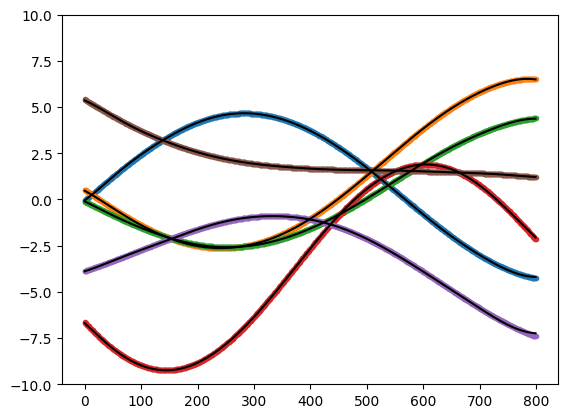

In [14]:
print(dissipation)
X_=Rede_Campos(time).cpu().detach().numpy()
plt.plot(np.transpose(fields_array[0:6,:]),'.')
for i in range(6):
    plt.plot(X_[:,i],"k")
plt.ylim(-10,10)


plt.show()
